<b> Fitting-and-Alignment-EN3160-Image-Processing-and-Computer-Vision-Sem-5 <b>

Index No: 230155J
<br>EN3160 Assignment 2
<br>**Github link :** <href>https://github.com/IdeaDP/Fitting-and-Alignment-EN3160-Image-Processing-and-Computer-Vision-Sem-5.git<ahref>


**Q1** Blob filtering using Laplacian of Gaussian

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
from matplotlib.pylab import maximum

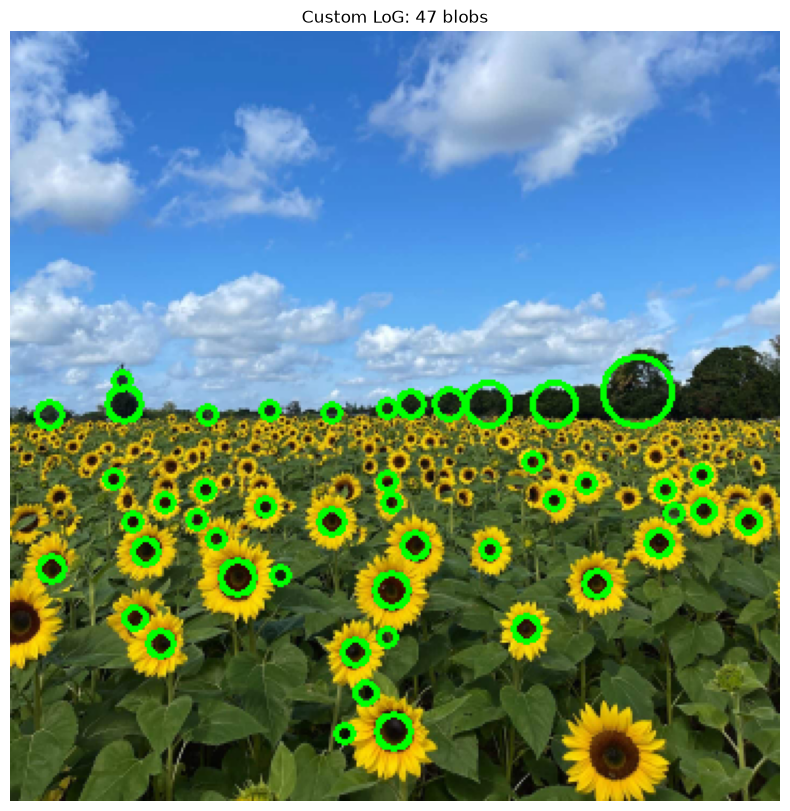

In [ ]:
sunflowers = cv.imread('the_berry_farms_sunflower_field.jpeg',cv.IMREAD_REDUCED_COLOR_4)

def log_kernel(sigma):
    radius = int(np.ceil(3 * sigma))
    y, x = np.mgrid[-radius:radius + 1, -radius:radius + 1]
    r2 = x**2 + y**2

    gaussian = np.exp(-r2 / (2 * sigma**2)) / (2 * np.pi * sigma**2)
    kernel = ((r2 - 2 * sigma**2) / sigma**4) * gaussian

    kernel -= kernel.mean()  
    return (sigma**2 * kernel).astype(np.float32)  


def detect_blobs(image, sigmas, threshold=0.2, dark_blobs=True):
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray = gray.astype(np.float32) / 255.0

    responses = []
    for sigma in sigmas:
        response = cv.filter2D(
            gray, cv.CV_32F, log_kernel(sigma),
            borderType=cv.BORDER_REFLECT101
        )
        responses.append(response if dark_blobs else -response)

    responses = np.stack(responses)
    peak = responses.max()
    if peak <= 0:
        return []

    local_max = np.stack([
        cv.dilate(response, np.ones((3, 3), np.uint8))
        for response in responses
    ])

    candidates = []
    for i, sigma in enumerate(sigmas):
        neighborhood_max = local_max[
            max(0, i - 1):min(len(sigmas), i + 2)
        ].max(axis=0)

        mask = (
            (responses[i] == neighborhood_max) &
            (responses[i] > threshold * peak)
        )

        # Ignore detections whose filter extends beyond the image
        border = int(np.ceil(3 * sigma))
        mask[:border, :] = False
        mask[-border:, :] = False
        mask[:, :border] = False
        mask[:, -border:] = False

        ys, xs = np.where(mask)
        radius = np.sqrt(2) * sigma

        for y, x in zip(ys, xs):
            candidates.append(
                (int(x), int(y), float(radius), float(responses[i, y, x]))
            )

    # Keep the strongest detection when nearby scales detect the same blob
    candidates.sort(key=lambda blob: blob[3], reverse=True)
    blobs = []

    for x, y, radius, score in candidates:
        if all(
            np.hypot(x - bx, y - by) > max(radius, br)
            for bx, by, br, _ in blobs
        ):
            blobs.append((x, y, radius, score))

    return blobs


# Sigma controls blob size: detected radius is approximately sqrt(2) * sigma
sigmas = np.geomspace(3, 20, 15)
blobs = detect_blobs(
    sunflowers, sigmas, threshold=0.5, dark_blobs=True
)

result = sunflowers.copy()
for x, y, radius, _ in blobs:
    cv.circle(result, (x, y), int(round(radius)), (0, 255, 0), 2)

plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title(f"Custom LoG: {len(blobs)} blobs")
plt.axis("off")
plt.show()

In [30]:
gray = cv.cvtColor(sunflowers, cv.COLOR_BGR2GRAY)
gray = gray.astype(np.float32) / 255.0

# 1. Choose the range of scales
sigmas = np.arange(3, 31, 2)  # 3, 5, ..., 29
responses = []

# 2. Apply a custom, scale-normalized LoG filter
for sigma in sigmas:
    half_size = int(np.ceil(3 * sigma))
    y, x = np.mgrid[
        -half_size:half_size + 1,
        -half_size:half_size + 1
    ]
    r2 = x*x + y*y

    gaussian = np.exp(-r2 / (2*sigma**2)) / (2*np.pi*sigma**2)
    kernel = ((r2 - 2*sigma**2) / sigma**4) * gaussian
    kernel -= kernel.mean()
    kernel *= sigma**2  # Make responses comparable across scales

    response = cv.filter2D(
        gray, cv.CV_32F, kernel.astype(np.float32)
    )
    responses.append(response)

responses = np.stack(responses)

# Positive LoG peaks detect dark blobs.
# For bright blobs, uncomment the following:
# responses = -responses

# 3. Find maxima across scale, height, and width
local_max = maximum_filter(responses, size=(3, 3, 3))
threshold = 0.2 * max(float(responses.max()), 0)

peaks = (responses == local_max) & (responses > threshold)

# Ignore borders where the filter extends beyond the image
for i, sigma in enumerate(sigmas):
    border = int(np.ceil(3 * sigma))
    peaks[i, :border, :] = False
    peaks[i, -border:, :] = False
    peaks[i, :, :border] = False
    peaks[i, :, -border:] = False

# 4. Collect candidate circles
scale_indices, ys, xs = np.where(peaks)

candidates = []
for i, y, x in zip(scale_indices, ys, xs):
    sigma = float(sigmas[i])
    radius = np.sqrt(2) * sigma
    score = float(responses[i, y, x])
    candidates.append((int(x), int(y), radius, sigma, score))

# Keep the strongest detection for nearby centers
candidates.sort(key=lambda circle: circle[4], reverse=True)
circles = []

for circle in candidates:
    x, y, radius, sigma, score = circle

    if all(
        np.hypot(x - c[0], y - c[1]) > max(radius, c[2])
        for c in circles
    ):
        circles.append(circle)

# 5. Select the five largest circles
circles.sort(key=lambda circle: circle[2], reverse=True)
largest = circles[:5]

# 6. Report parameters
print(f"Sigma range: {sigmas[0]} to {sigmas[-1]} pixels")
print(f"Sigma step: {sigmas[1] - sigmas[0]} pixels")
print("\nLargest circles:")
print("No.    x      y     Radius     Sigma")

for number, (x, y, radius, sigma, score) in enumerate(largest, 1):
    print(f"{number:<5} {x:<6} {y:<6} {radius:<10.2f} {sigma:.2f}")

# 7. Draw and label the reported circles
result = sunflowers.copy()

for number, (x, y, radius, sigma, score) in enumerate(largest, 1):
    cv.circle(result, (x, y), int(round(radius)), (0, 255, 0), 2)
    cv.putText(
        result, str(number), (x, y),
        cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2
    )



Sigma range: 3 to 29 pixels
Sigma step: 2 pixels

Largest circles:
No.    x      y     Radius     Sigma
1     293    169    18.38      13.00
2     262    307    12.73      9.00
3     282    338    9.90       7.00
4     106    255    9.90       7.00
5     179    327    9.90       7.00


Q2 RANSAC fitting a line and a circle

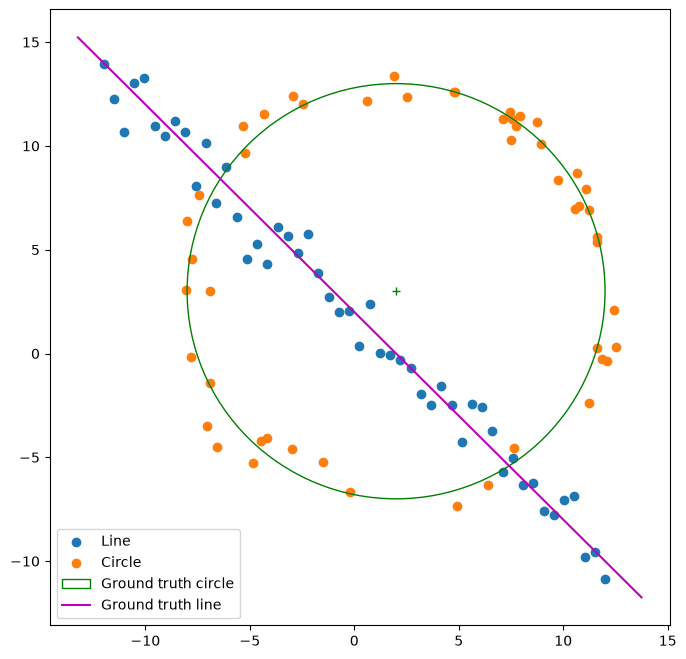

In [14]:
import numpy as np
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt

# Uncomment for repeatable results
# np.random.seed(0)

N = 100
half_n = N // 2

# Generate noisy circle points
r = 10
x0_gt, y0_gt = 2, 3
s = r / 16

t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)

x = x0_gt + (r + n) * np.cos(t)
y = y0_gt + (r + n) * np.sin(t)

X_circ = np.hstack((
    x.reshape(half_n, 1),
    y.reshape(half_n, 1)
))

# Generate noisy line points
s = 1.
m, b = -1, 2

x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)

X_line = np.hstack((
    x.reshape(half_n, 1),
    y.reshape(half_n, 1)
))

# Combine all points
X = np.vstack((X_circ, X_line))

# Plot the points
fig, ax = plt.subplots(1, 1, figsize=(8, 8))

ax.scatter(X_line[:, 0], X_line[:, 1], label="Line")
ax.scatter(X_circ[:, 0], X_circ[:, 1], label="Circle")

# Plot the ground-truth circle
circle_gt = plt.Circle(
    (x0_gt, y0_gt),
    r,
    color="g",
    fill=False,
    label="Ground truth circle"
)
ax.add_patch(circle_gt)
ax.plot(x0_gt, y0_gt, "+", color="g")

# Plot the ground-truth line
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m * x_ + b

ax.plot(x_, y_, color="m", label="Ground truth line")
ax.legend()

plt.show()

**2(a)** Line estimation using RANSAC

In [15]:

def ransac_line(X, threshold=1.5, iterations=200,
                min_inliers=35, seed=0):

    rng = np.random.default_rng(seed)

    best_inliers = None
    best_count = 0
    best_error = np.inf
    best_sample = None
    best_candidate = None

    for _ in range(iterations):

        # 1. Randomly select two points
        indices = rng.choice(len(X), size=2, replace=False)
        p1, p2 = X[indices]

        # 2. Calculate a normal to the candidate line
        dx, dy = p2 - p1
        normal = np.array([dy, -dx], dtype=float)
        length = np.linalg.norm(normal)

        if length < 1e-10:
            continue

        # Normalize so that a² + b² = 1
        a, b = normal / length
        d = a * p1[0] + b * p1[1]

        # 3. Calculate perpendicular distances
        distances = np.abs(a * X[:, 0] + b * X[:, 1] - d)

        # 4. Find the consensus set
        inliers = distances < threshold
        count = np.count_nonzero(inliers)

        if count < min_inliers:
            continue

        error = np.mean(distances[inliers] ** 2)

        # 5. Save the best candidate
        if count > best_count or (
            count == best_count and error < best_error
        ):
            best_count = count
            best_error = error
            best_inliers = inliers.copy()
            best_sample = X[indices].copy()
            best_candidate = np.array([a, b, d])

    if best_inliers is None:
        raise ValueError(
            "No acceptable line found. Check the RANSAC settings."
        )

    # 6. Refit using total least squares on the winning consensus
    points = X[best_inliers]
    centroid = points.mean(axis=0)
    centered = points - centroid

    _, _, Vt = np.linalg.svd(centered, full_matrices=False)

    # Last right singular vector: direction of smallest variation
    a, b = Vt[-1]
    d = np.dot([a, b], centroid)

    # Make d a nonnegative distance from the origin
    if d < 0:
        a, b, d = -a, -b, -d

    return {
        "line": np.array([a, b, d]),
        "inliers": best_inliers,
        "sample": best_sample,
        "candidate": best_candidate
    }


# Apply to the combined point set from Listing 1
result = ransac_line(X)

a, b, d = result["line"]

print(f"Estimated line: {a:.4f}x + {b:.4f}y = {d:.4f}")
print(f"Normal length: {np.hypot(a, b):.4f}")
print(f"Consensus size: {np.count_nonzero(result['inliers'])}")

Estimated line: 0.7038x + 0.7104y = 1.3396
Normal length: 1.0000
Consensus size: 51


**2(b)** Estimating the circle 

In [16]:
# Remove line inliers
points = X[~result["inliers"]]

threshold = 1.25
iterations = 500
min_inliers = 25

rng = np.random.default_rng(0)
best_count = 0
best_error = np.inf
best_circle = None

for _ in range(iterations):

    # Select three random points
    sample = points[rng.choice(len(points), 3, replace=False)]
    p1, p2, p3 = sample

    # Calculate the circle center
    A = 2 * np.array([p2 - p1, p3 - p1])
    B = np.array([
        np.dot(p2, p2) - np.dot(p1, p1),
        np.dot(p3, p3) - np.dot(p1, p1)
    ])

    # Skip nearly collinear points
    if np.linalg.cond(A) > 1e6:
        continue

    center = np.linalg.solve(A, B)
    radius = np.linalg.norm(p1 - center)

    # Calculate distance from each point to the circumference
    errors = np.abs(
        np.linalg.norm(points - center, axis=1) - radius
    )

    inliers = errors < threshold
    count = np.sum(inliers)

    if count < min_inliers:
        continue

    error = np.mean(errors[inliers] ** 2)

    # Save the strongest consensus
    if count > best_count or (
        count == best_count and error < best_error
    ):
        best_count = count
        best_error = error
        best_circle = [center[0], center[1], radius]
        best_inliers = inliers.copy()
        best_sample = sample.copy()

if best_circle is None:
    raise ValueError("No circle found. Check the RANSAC settings.")

# Refine the circle using its inliers
circle_points = points[best_inliers]

def circle_error(parameters):
    cx, cy, radius = parameters
    distances = np.linalg.norm(circle_points - [cx, cy], axis=1)
    return np.sum((distances - radius) ** 2)

fit = minimize(
    circle_error,
    best_circle,
    method="L-BFGS-B",
    bounds=[(None, None), (None, None), (1e-6, None)]
)

if not fit.success:
    raise RuntimeError(fit.message)

cx, cy, radius = fit.x

print(f"Center: ({cx:.3f}, {cy:.3f})")
print(f"Radius: {radius:.3f}")
print(f"Number of inliers: {best_count}")

Center: (2.068, 2.939)
Radius: 10.050
Number of inliers: 46


**2(c)** Plotting the line and Circle in the same graph

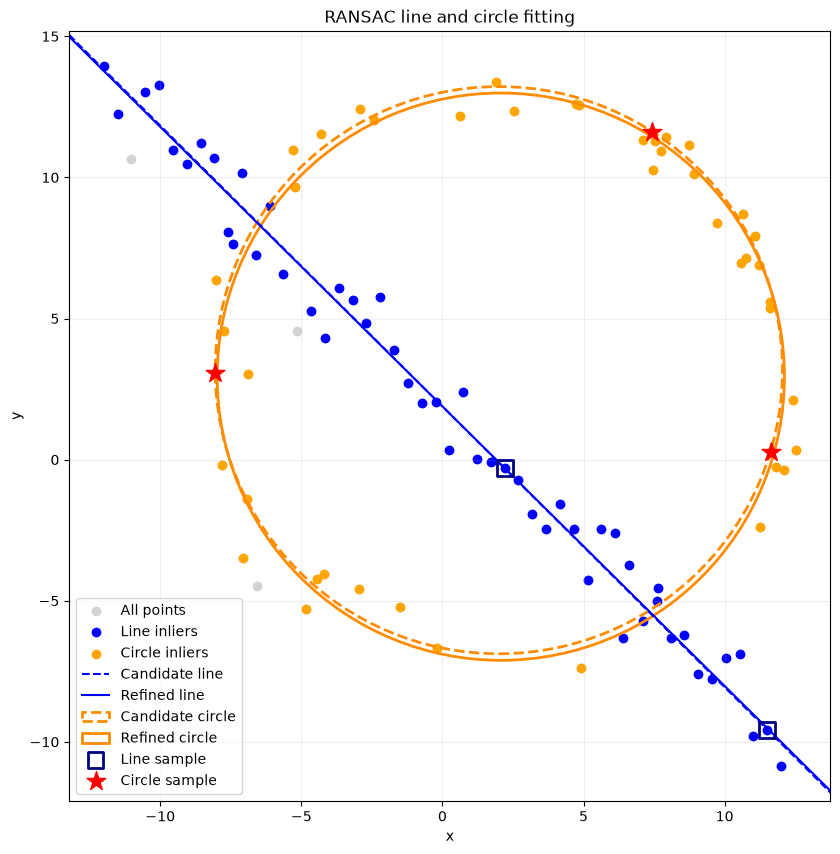

In [17]:
fig, ax = plt.subplots(figsize=(10, 10))

# All points and the two consensus sets
ax.scatter(X[:, 0], X[:, 1], c="lightgray", label="All points")

line_points = X[result["inliers"]]
ax.scatter(
    line_points[:, 0], line_points[:, 1],
    c="blue", label="Line inliers"
)

circle_points = points[best_inliers]
ax.scatter(
    circle_points[:, 0], circle_points[:, 1],
    c="orange", label="Circle inliers"
)

# Save limits before drawing the models
x_limits = ax.get_xlim()
y_limits = ax.get_ylim()
x_values = np.linspace(*x_limits, 200)

# Candidate and refined lines
for parameters, style, label in [
    (result["candidate"], "--", "Candidate line"),
    (result["line"], "-", "Refined line")
]:
    a, b, d = parameters

    if abs(b) > 1e-8:
        ax.plot(
            x_values, (d - a * x_values) / b,
            color="blue", linestyle=style, label=label
        )
    else:
        ax.axvline(
            d / a, color="blue", linestyle=style, label=label
        )

# Candidate and refined circles
for parameters, style, label in [
    (best_circle, "--", "Candidate circle"),
    (fit.x, "-", "Refined circle")
]:
    cx, cy, radius = parameters
    ax.add_patch(plt.Circle(
        (cx, cy), radius,
        fill=False, color="darkorange",
        linestyle=style, linewidth=2, label=label
    ))

# Winning samples
line_sample = result["sample"]

ax.scatter(
    line_sample[:, 0], line_sample[:, 1],
    marker="s", s=130, facecolors="none",
    edgecolors="navy", linewidths=2,
    label="Line sample", zorder=5
)

ax.scatter(
    best_sample[:, 0], best_sample[:, 1],
    marker="*", s=200, c="red",
    label="Circle sample", zorder=5
)

ax.set_xlim(x_limits)
ax.set_ylim(y_limits)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("RANSAC line and circle fitting")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

**2(d)** What happens if you fit the circle **before** the line.

The main risk is that a large circle can approximate a straight line over a short arc. RANSAC can find a large circle supported by many line points, instead of the intended circle.

If those points are then removed as circle inliers, the remaining data may no longer contain enough line points for an accurate line fit.


**Q3** Super-imposing the image to building

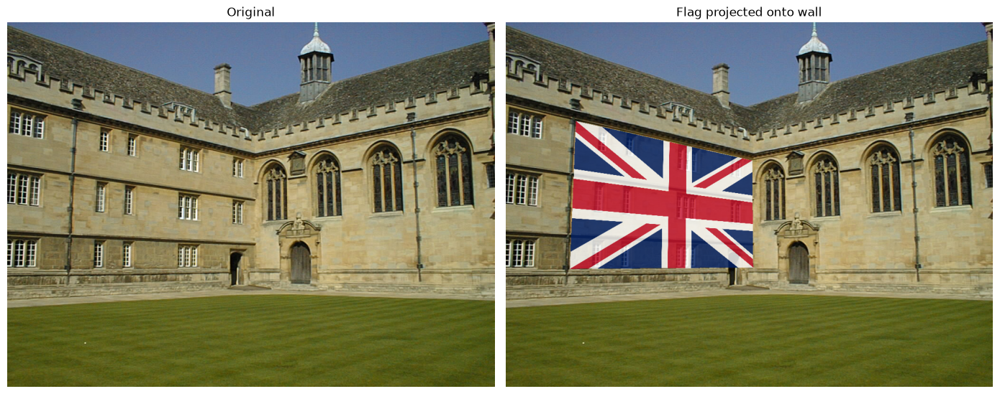

Selected destination points:
 [[148. 208.]
 [518. 291.]
 [520. 516.]
 [135. 519.]]
Homography matrix:
 [[ 2.95835501e-01 -1.93195092e-02  1.48000000e+02]
 [ 1.01129653e-01  3.02137833e-01  2.08000000e+02]
 [ 1.98893333e-04 -4.26942367e-05  1.00000000e+00]]


In [ ]:
# Load source and background images
flag = cv.imread(r"E:\Downloads\a2images\a2images\flag.png")
background = cv.imread(r"E:\Downloads\a2images\a2images\wadham.jpg")

if flag is None or background is None:
    raise FileNotFoundError("Check the image paths.")

# 1. Select four destination points
selected = []
window = "Select four wall corners"


def select_point(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN and len(selected) < 4:
        selected.append((x, y))


cv.namedWindow(window, cv.WINDOW_AUTOSIZE)
cv.setMouseCallback(window, select_point)

while True:
    preview = background.copy()

    for number, point in enumerate(selected, 1):
        cv.circle(preview, point, 5, (0, 0, 255), -1)
        cv.putText(
            preview, str(number), (point[0] + 8, point[1] - 8),
            cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2
        )

    if len(selected) > 1:
        cv.polylines(
            preview, [np.array(selected, dtype=np.int32)],
            len(selected) == 4, (0, 255, 0), 2
        )

    cv.imshow(window, preview)
    key = cv.waitKey(20) & 0xFF

    if key == 27:
        cv.destroyAllWindows()
        raise SystemExit("Selection cancelled.")

    if key == ord("r"):
        selected.clear()

    if len(selected) == 4:
        break

cv.destroyAllWindows()

# 2. Define corresponding source and destination corners
h, w = flag.shape[:2]

source_points = np.float32([
    [0, 0],
    [w - 1, 0],
    [w - 1, h - 1],
    [0, h - 1]
])

destination_points = np.float32(selected)

# Check that the selected region is a valid convex quadrilateral
polygon = np.array(selected, dtype=np.int32)
if not cv.isContourConvex(polygon) or cv.contourArea(polygon) < 10:
    raise ValueError("Select four corners in order around a valid region.")

# 3. Calculate the homography
H = cv.getPerspectiveTransform(source_points, destination_points)

# 4. Warp the flag onto a canvas the size of the background
height, width = background.shape[:2]

warped_flag = cv.warpPerspective(
    flag, H, (width, height)
)

# 5. Warp a mask to identify the flag region
source_mask = np.full((h, w), 255, dtype=np.uint8)

warped_mask = cv.warpPerspective(
    source_mask, H, (width, height),
    flags=cv.INTER_NEAREST
)

# 6. Blend only inside the selected region
alpha = 0.8

blended = cv.addWeighted(
    warped_flag, alpha,
    background, 1 - alpha,
    0
)

result = background.copy()
result[warped_mask > 0] = blended[warped_mask > 0]

# 7. Display the original and composite
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(cv.cvtColor(background, cv.COLOR_BGR2RGB))
axes[0].set_title("Original")

axes[1].imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
axes[1].set_title("Flag projected onto wall")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Selected destination points:\n", destination_points)
print("Homography matrix:\n", H)

**Q4** PCB image allignment 

**Q4(a)** Identifying SIFT features 

AECC1.jpg: 14272 keypoints
AAAA1.jpg: 2414 keypoints
ADAD1.jpg: 8486 keypoints
AECC2.jpg: 12315 keypoints
AECC3.jpg: 15198 keypoints
AECC4.jpg: 11610 keypoints


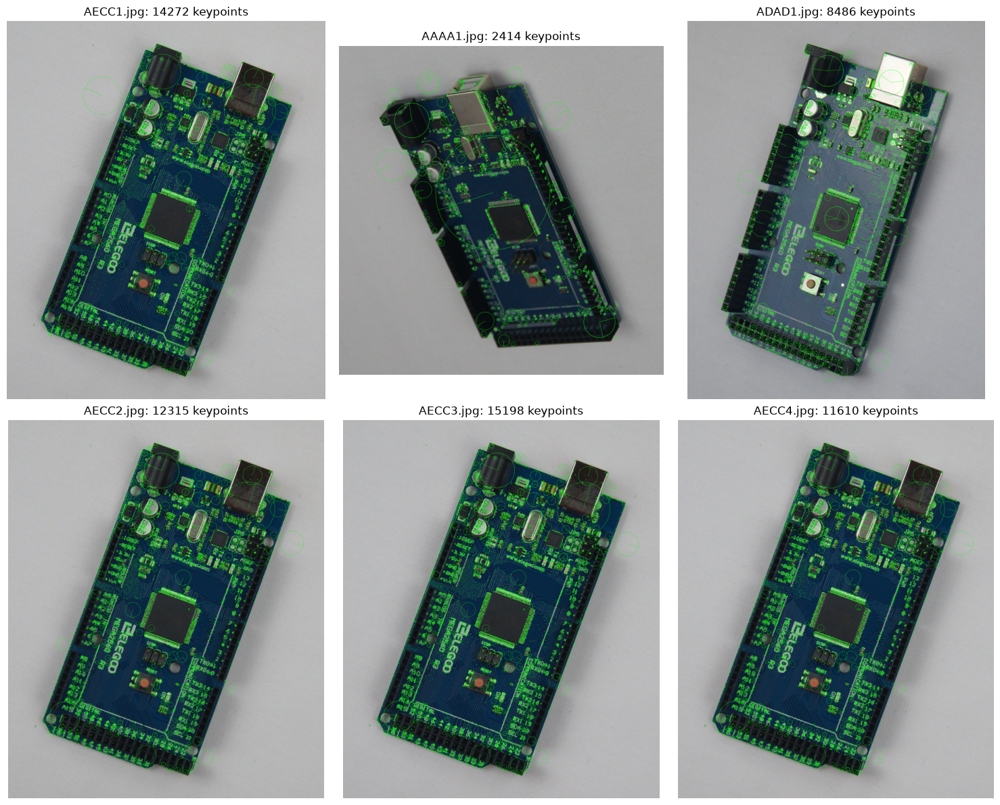

In [20]:

from pathlib import Path
folder = Path(r"E:\Downloads\a2images\a2images\pcbs")

filenames = [
    "AECC1.jpg",  # Template
    "AAAA1.jpg",
    "ADAD1.jpg",
    "AECC2.jpg",
    "AECC3.jpg",
    "AECC4.jpg"
]

# Create the SIFT detector
sift = cv.SIFT_create()

# Store images, keypoints, and descriptors for later matching
features = {}

fig, axes = plt.subplots(2, 3, figsize=(15, 12))

for ax, filename in zip(axes.flat, filenames):

    image = cv.imread(str(folder / filename))

    if image is None:
        raise FileNotFoundError(f"Could not load {filename}")

    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

    # Detect keypoints and calculate their descriptors
    keypoints, descriptors = sift.detectAndCompute(gray, None)

    features[filename] = {
        "image": image,
        "gray": gray,
        "keypoints": keypoints,
        "descriptors": descriptors
    }

    # Draw keypoint locations, sizes, and orientations
    marked = cv.drawKeypoints(
        image,
        keypoints,
        None,
        color=(0, 255, 0),
        flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )

    ax.imshow(cv.cvtColor(marked, cv.COLOR_BGR2RGB))
    ax.set_title(f"{filename}: {len(keypoints)} keypoints")
    ax.axis("off")

    print(f"{filename}: {len(keypoints)} keypoints")

plt.tight_layout()
plt.show()

**Q4(b)** Matching Features with RANSAC

AAAA1.jpg: 51 ratio-test matches, 18 RANSAC inliers


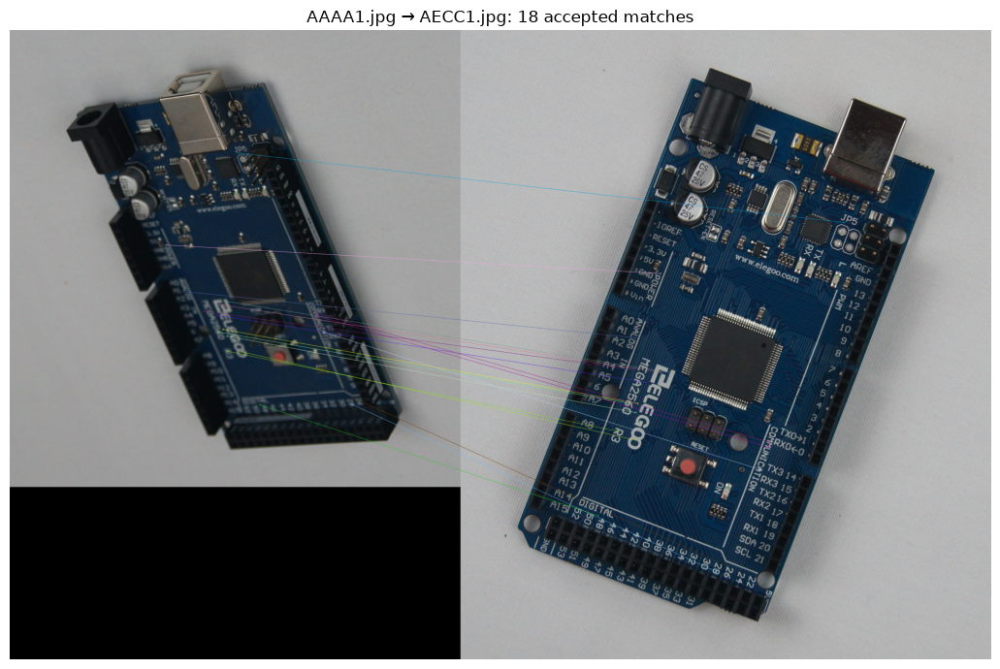

ADAD1.jpg: 369 ratio-test matches, 194 RANSAC inliers


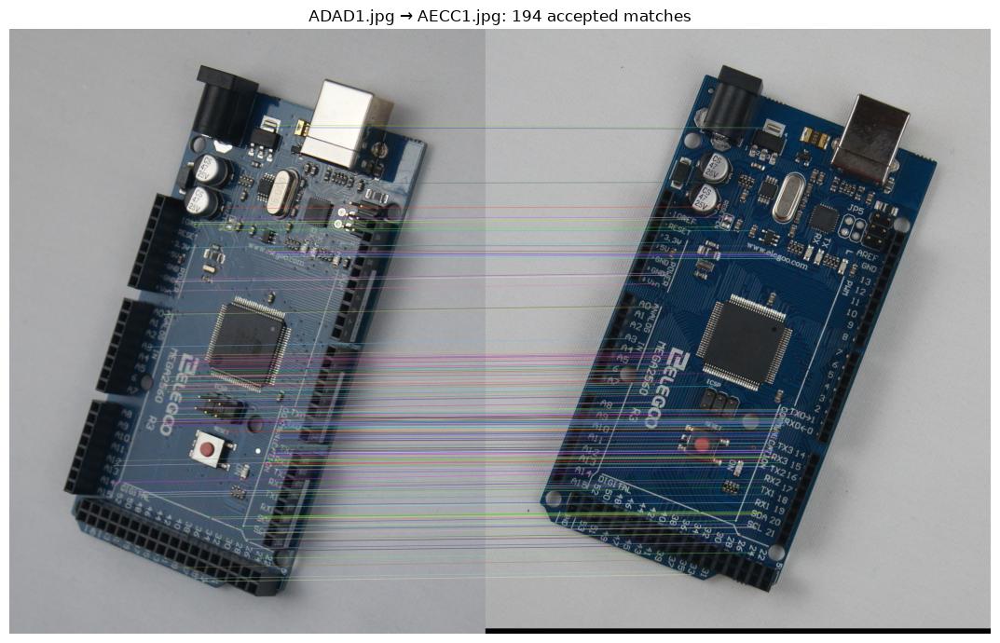

AECC2.jpg: 4322 ratio-test matches, 3847 RANSAC inliers


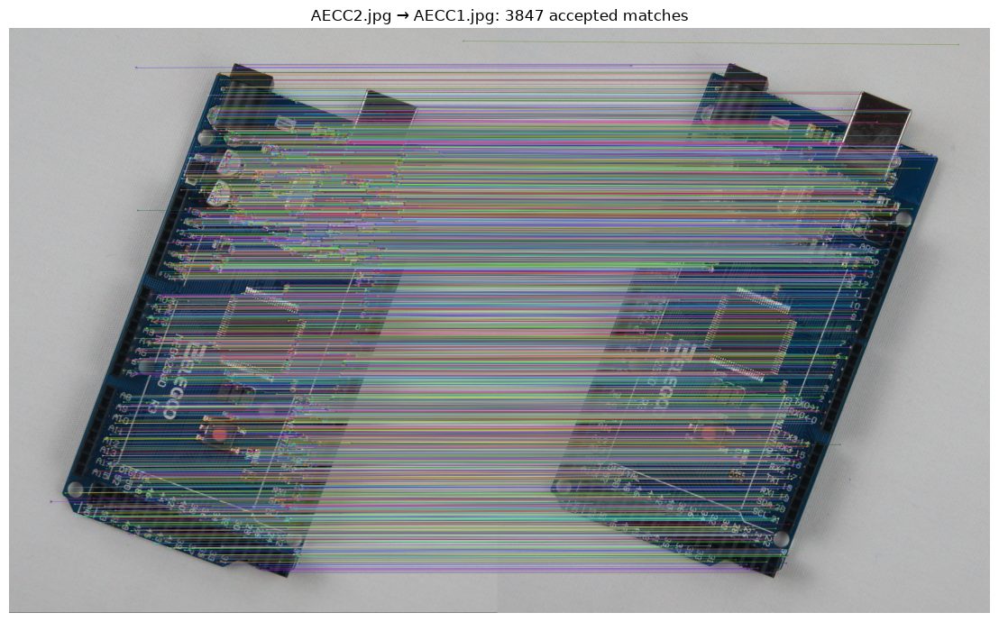

AECC3.jpg: 5629 ratio-test matches, 5006 RANSAC inliers


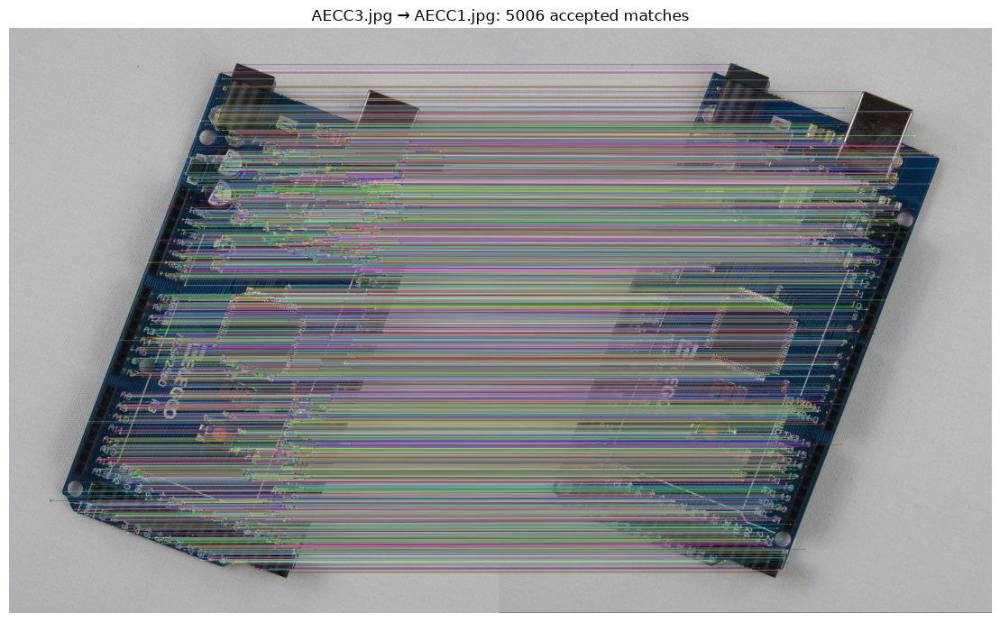

AECC4.jpg: 3830 ratio-test matches, 3402 RANSAC inliers


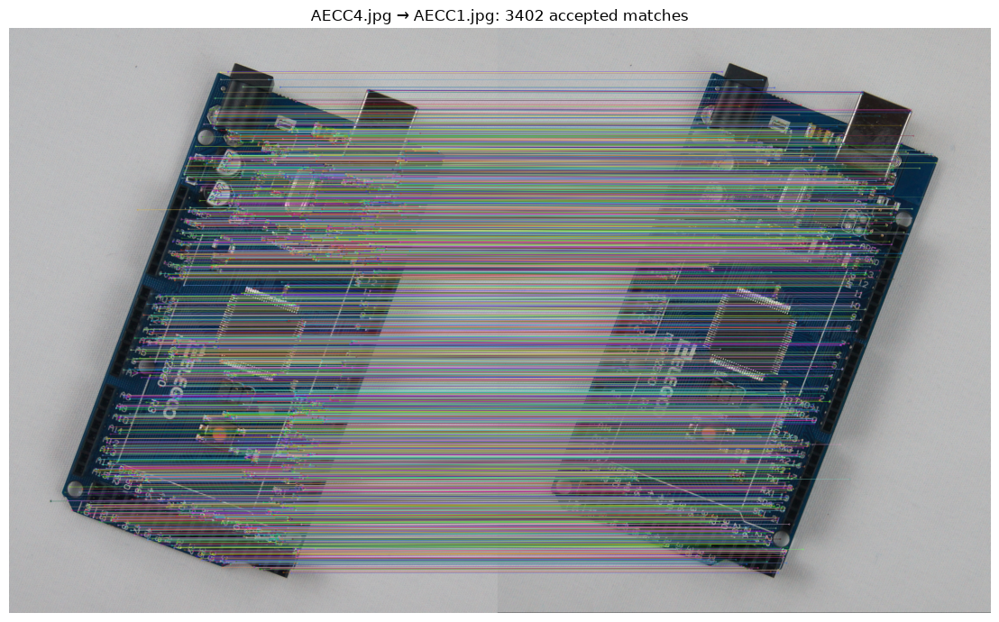

In [21]:
import numpy as np

template = features["AECC1.jpg"]

# SIFT descriptors use Euclidean (L2) distance
matcher = cv.BFMatcher(cv.NORM_L2)

# Store results for part 4(c)
matching_results = {}

for filename in filenames:

    if filename == "AECC1.jpg":
        continue

    pcb = features[filename]

    if (
        pcb["descriptors"] is None or
        template["descriptors"] is None or
        len(template["descriptors"]) < 2
    ):
        print(f"{filename}: insufficient descriptors")
        continue

    # 1. Find the two nearest template matches for each PCB feature
    pairs = matcher.knnMatch(
        pcb["descriptors"],
        template["descriptors"],
        k=2
    )

    # 2. Apply Lowe's ratio test to reject ambiguous matches
    good_matches = []

    for pair in pairs:
        if len(pair) == 2:
            first, second = pair

            if first.distance < 0.75 * second.distance:
                good_matches.append(first)

    if len(good_matches) < 4:
        print(f"{filename}: not enough matches")
        continue

    # 3. Extract corresponding coordinates
    pcb_points = np.float32([
        pcb["keypoints"][m.queryIdx].pt
        for m in good_matches
    ]).reshape(-1, 1, 2)

    template_points = np.float32([
        template["keypoints"][m.trainIdx].pt
        for m in good_matches
    ]).reshape(-1, 1, 2)

    # 4. Estimate the homography: PCB -> template
    H, mask = cv.findHomography(
        pcb_points,
        template_points,
        cv.RANSAC,
        5.0
    )

    if H is None or mask is None:
        print(f"{filename}: homography estimation failed")
        continue

    # 5. Store the transformation and matches
    matching_results[filename] = {
        "H": H,
        "matches": good_matches,
        "inlier_mask": mask.ravel().astype(bool)
    }

    # 6. Draw only the matches accepted by RANSAC
    match_image = cv.drawMatches(
        pcb["image"],
        pcb["keypoints"],
        template["image"],
        template["keypoints"],
        good_matches,
        None,
        matchesMask=mask.ravel().tolist(),
        flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    inlier_count = int(mask.sum())

    print(
        f"{filename}: {len(good_matches)} ratio-test matches, "
        f"{inlier_count} RANSAC inliers"
    )

    plt.figure(figsize=(14, 7))
    plt.imshow(cv.cvtColor(match_image, cv.COLOR_BGR2RGB))
    plt.title(
        f"{filename} → AECC1.jpg: "
        f"{inlier_count} accepted matches"
    )
    plt.axis("off")
    plt.tight_layout()
    plt.show()

**Q4(c)** Warping and Computing the difference between template and images.

In [ ]:

template_image = features["AECC1.jpg"]["image"]
template_gray = features["AECC1.jpg"]["gray"]

height, width = template_gray.shape

# Store outputs for later comparison
alignment_results = {}

for filename, match_result in matching_results.items():

    pcb_image = features[filename]["image"]
    H = match_result["H"]

    # 1. Warp the PCB image into the template coordinates
    aligned = cv.warpPerspective(
        pcb_image, H, (width, height)
    )

    aligned_gray = cv.cvtColor(aligned, cv.COLOR_BGR2GRAY)

    # 2. Find the region covered by the warped PCB photograph
    source_mask = np.full(
        pcb_image.shape[:2], 255, dtype=np.uint8
    )

    warped_mask = cv.warpPerspective(
        source_mask, H, (width, height),
        flags=cv.INTER_NEAREST
    )

    # Exclude a small boundary affected by interpolation
    warped_mask = cv.erode(
        warped_mask, np.ones((3, 3), dtype=np.uint8)
    )
    valid = warped_mask > 0

    # 3. Calculate the absolute grayscale difference
    difference = cv.absdiff(template_gray, aligned_gray)

    # Ignore areas without valid image coverage
    difference[~valid] = 0

    alignment_results[filename] = {
        "aligned": aligned,
        "difference": difference,
        "valid_mask": valid
    }

    # 4. Display results
    fig, axes = plt.subplots(1, 3, figsize=(15, 6))

    axes[0].imshow(cv.cvtColor(template_image, cv.COLOR_BGR2RGB))
    axes[0].set_title("Template: AECC1.jpg")

    axes[1].imshow(cv.cvtColor(aligned, cv.COLOR_BGR2RGB))
    axes[1].set_title(f"Aligned: {filename}")

    axes[2].imshow(difference, cmap="gray", vmin=0, vmax=255)
    axes[2].set_title("Absolute difference")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

**Q4(d)** Reporting Difference images

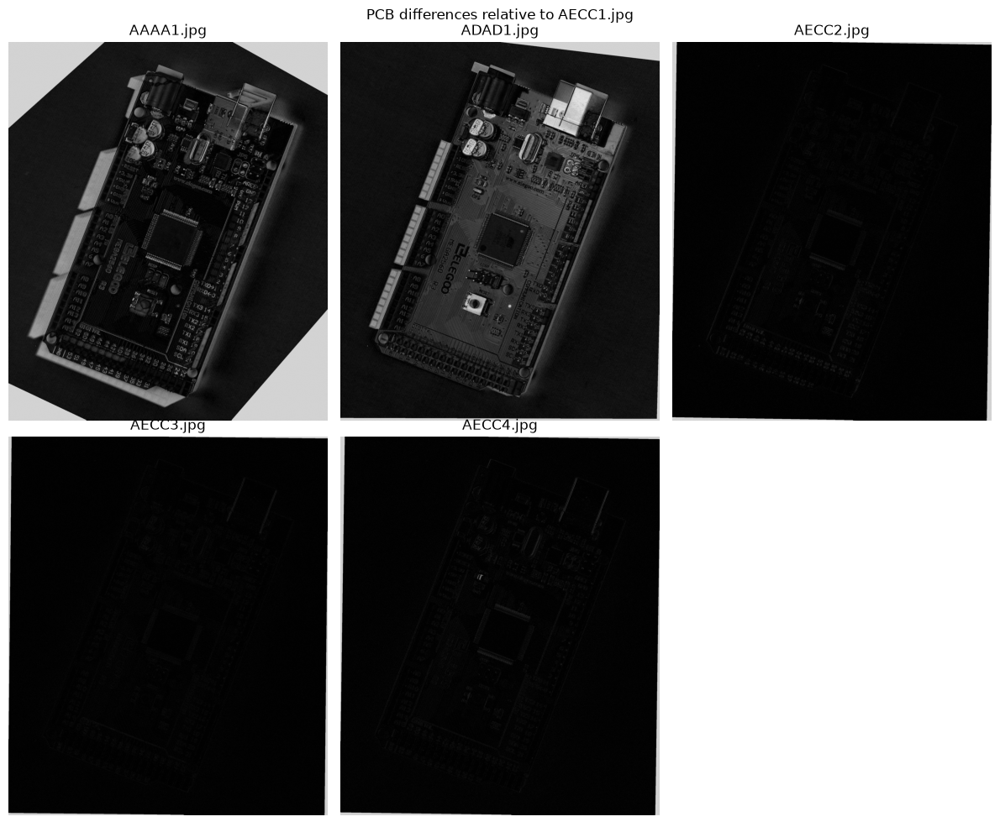

In [23]:
pcb_filenames = [
    "AAAA1.jpg",
    "ADAD1.jpg",
    "AECC2.jpg",
    "AECC3.jpg",
    "AECC4.jpg"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 10))

# Display excluded regions in gray
cmap = plt.get_cmap("gray").copy()
cmap.set_bad("lightgray")

for ax, filename in zip(axes.flat, pcb_filenames):

    if filename not in alignment_results:
        ax.set_title(f"{filename}: alignment unavailable")
        ax.axis("off")
        continue

    output = alignment_results[filename]

    # Mask regions without valid image coverage
    difference = np.ma.array(
        output["difference"],
        mask=~output["valid_mask"]
    )

    ax.imshow(difference, cmap=cmap, vmin=0, vmax=255)
    ax.set_title(filename)
    ax.axis("off")

# Hide the unused sixth panel
axes.flat[-1].axis("off")

fig.suptitle("PCB differences relative to AECC1.jpg")
plt.tight_layout()
plt.show()

# Optional: save the figure for your report
# fig.savefig("pcb_difference_images.png", dpi=200, bbox_inches="tight")

**Q4(e)** Some elements such as the USB Type B port,capacitors,and reset button show high difference.What could be the reason for this?

The homography approximately aligns the planar PCB surface. But the USB Type B port, capacitors, and reset button are placed above this plane. Changes in camera viewpoint causing components to misaligned after warping. Differences in reflections, shadows, and illumination can increase their pixel differences around metallic surfaces. Therefore a high difference in these regions does not necessarily indicate a defective or changed component.